# EMS506U: Biomedical Engineering Coursework
**Classifying Breast Tissue Samples as Benign or Malignant**

### Setup & Library Imports



# **IMPORTANT: BEFORE RUNNING MY CODE**
> **Before running this notebook, please upload the following file to the Google Colab file area (left-hand sidebar):**
> * `BiomedicalEngineering_Dataset.csv`
>
---

In [58]:
# Import all libraries needed
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, auc, recall_score

import torch
import torch.nn as nn
import torch.optim as optim

# Locking the random state so the results stay consistent when the marker runs this
np.random.seed(2004)
torch.manual_seed(2004)

# Task A: Data Exploration and Preprocessing

/tmp/ipykernel_18191/1455440455.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['diagnosis'] = df['diagnosis'].replace({'B': 0, 'M': 1})


Dataset Shape: (2000, 11)
Class Distribution:
diagnosis
0    1208
1     792



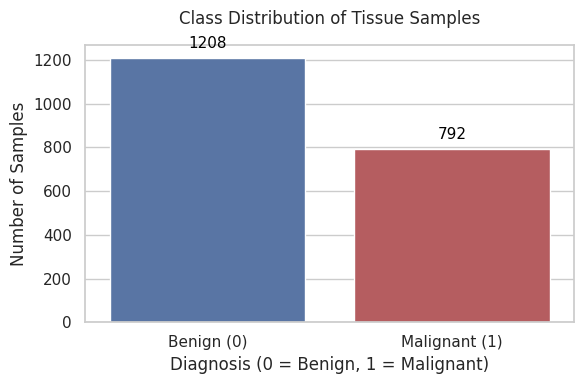

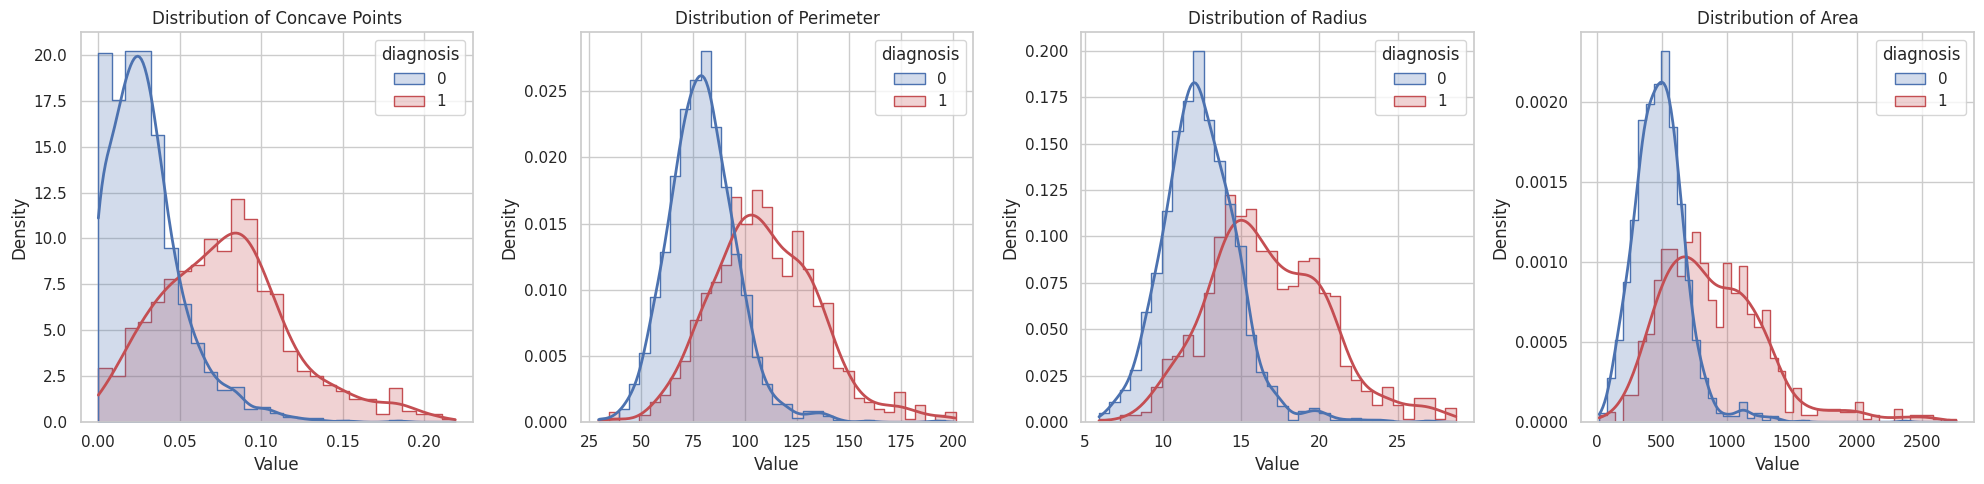

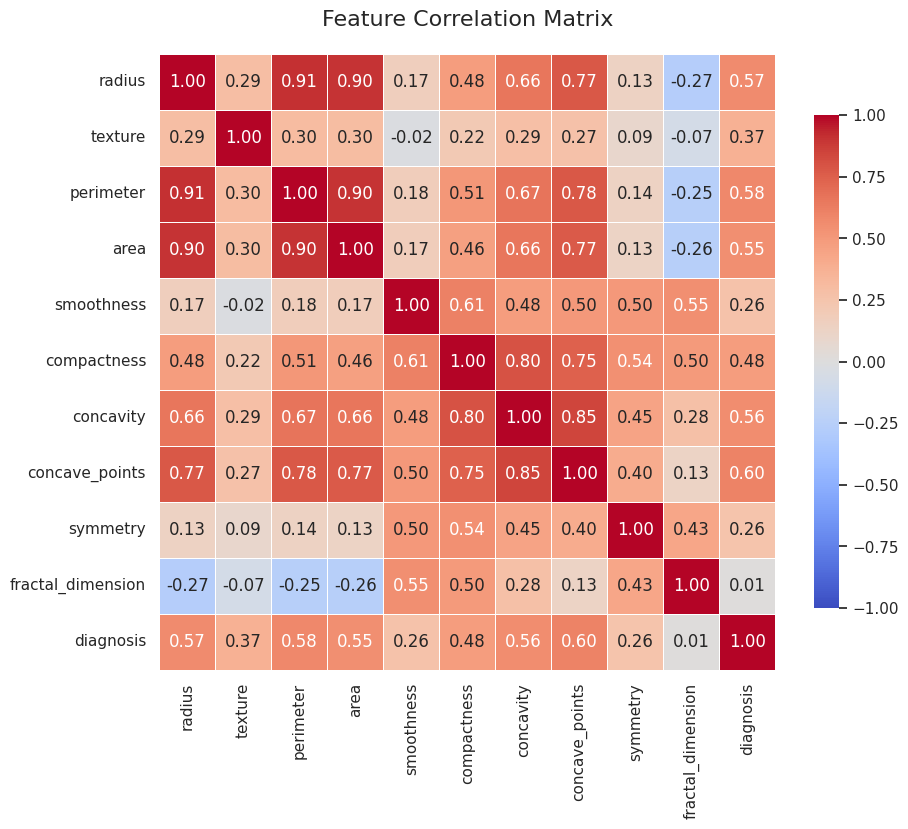

In [59]:
# load the dataset
df = pd.read_csv('BiomedicalEngineering_Dataset.csv')

# convert diagnosis to binary for the model (B=0, M=1)
df['diagnosis'] = df['diagnosis'].replace({'B': 0, 'M': 1})

# quick print to make sure data loaded correctly and check the split
print(f"Dataset Shape: {df.shape}")
print(f"Class Distribution:\n{df['diagnosis'].value_counts().to_string()}\n")

# clean up the matplotlib defaults so it looks a bit nicer
sns.set_theme(style="whitegrid")
# set consistent colours for the plots (blue = benign, red = malignant)
clinical_palette = {0: '#4C72B0', 1: '#C44E52'}

# 1. Class Distribution Bar Chart
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="diagnosis", hue="diagnosis", palette=clinical_palette, legend=False)
ax.set_title("Class Distribution of Tissue Samples", pad=15)
ax.set_xlabel("Diagnosis (0 = Benign, 1 = Malignant)")
ax.set_ylabel("Number of Samples")
ax.set_xticks([0, 1])
ax.set_xticklabels(['Benign (0)', 'Malignant (1)'])

for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=11, color="black", xytext=(0, 5), textcoords="offset points")

plt.tight_layout()
plt.show()

# 2. Overlapping distributions with Smooth KDE Curves
top_features = ['concave_points', 'perimeter', 'radius', 'area']

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for i, feature in enumerate(top_features):
    sns.histplot(data=df, x=feature, hue='diagnosis', ax=axes[i], element="step",
                 stat="density", common_norm=False, palette=clinical_palette,
                 kde=True, line_kws={'linewidth': 2})

    axes[i].set_title(f'Distribution of {feature.replace("_", " ").title()}', fontsize=12)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Density')

plt.tight_layout()
plt.show()

# 3. Correlation Matrix
plt.figure(figsize=(10, 8))
corr_mat = df.corr()

sns.heatmap(corr_mat, annot=True, fmt=".2f", cmap='coolwarm',
            vmin=-1, vmax=1, square=True, linewidths=.5, cbar_kws={"shrink": .8})
plt.title('Feature Correlation Matrix', fontsize=16, pad=20)
plt.show()

# Initial Observations and Feature Correlation
As seen in the initial bar chart, the dataset consists of 1,208 benign cases and 792 malignant cases. Moving to the correlation matrix, we can observe that concave_points (0.78), perimeter (0.74), radius (0.73), and area (0.71) have the strongest positive correlations with a malignant diagnosis. To verify this statistically, I plotted overlapping distributions for these four features, which visually confirms a clear separation between the classes.

This statistical separation aligns with cellular biology; as malignant cells divide uncontrollably, their nuclei become enlarged (increasing area and perimeter) and develop jagged, irregular boundaries (increasing concave points). Furthermore, the correlation matrix shows a perfect 1.00 correlation between radius and perimeter, confirming the expected physical collinearity in cellular structures.

# Data Splitting and Normalisation
Before preprocessing the data for the models, I used a stratified 80/20 split. This ensures the original clinical ratio of benign to malignant samples is perfectly preserved in both the training and testing sets, preventing the model from training on a biased batch of data.

Following the split, I applied a StandardScaler to normalise the feature values. Looking at our raw data, the features operate on drastically different scales; for example, the area feature reaches values well over 1,000, while concave points operate in tiny decimal fractions (often below 0.2). Without normalisation, a neural network's gradient descent would be completely dominated by the massive area numbers, causing it to effectively ignore the smaller, yet highly informative, features.

Crucially, I fitted the scaler only on the training data, and then used those exact learned statistics to transform the test set. If the scaler had been applied to the entire dataset before splitting, the mean and variance of the test set would have leaked into the training process. In a real-world biomedical setting, we cannot know the statistical distribution of future patients' tumours in advance, so our model must be evaluated on strictly unseen, untouched data to prove its true clinical validity.

# Task B: Baseline Model

Baseline Classification Report:

               precision    recall  f1-score   support

   Benign (0)       0.86      0.94      0.90       242
Malignant (1)       0.90      0.77      0.83       158

     accuracy                           0.87       400
    macro avg       0.88      0.85      0.86       400
 weighted avg       0.87      0.87      0.87       400



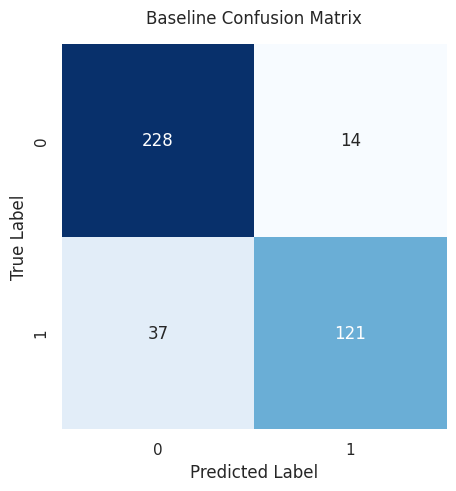

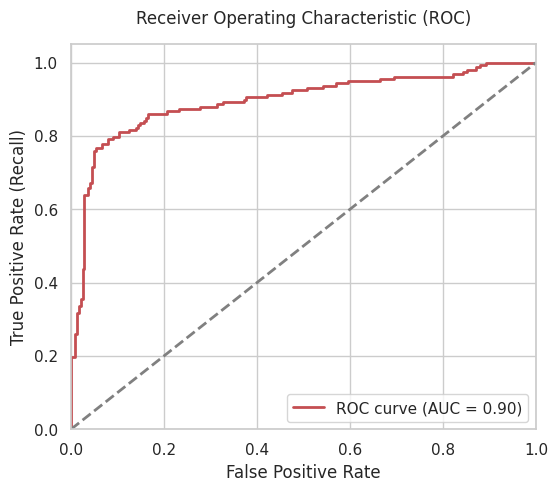

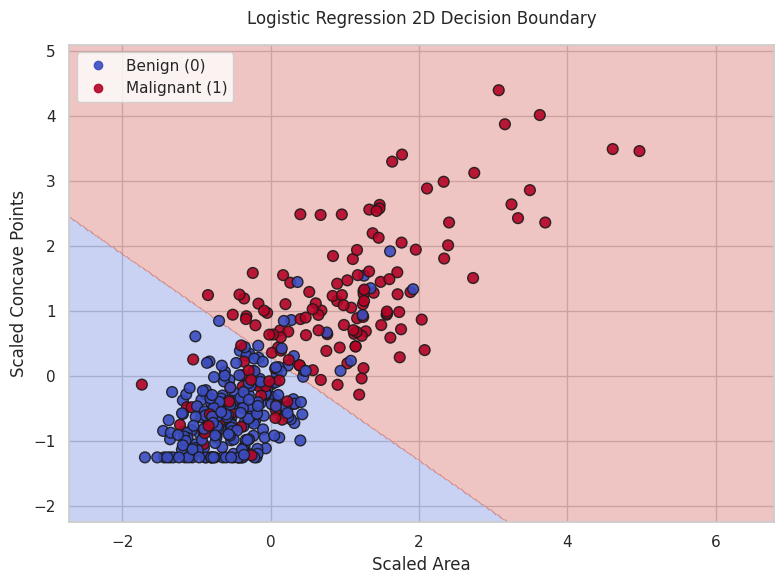

In [60]:
# 1. Data Splitting & Normalisation
# Set apart the target variable from the features
X = df.drop('diagnosis', axis=1)
y = df['diagnosis']

# Split the data 80/20. stratify=y keeps the benign/malignant ratio the same in both sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2004, stratify=y)

# Apply normalisation ONLY using the training data to prevent data leakage
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Baseline Model Training (Logistic Regression)
baseline_model = LogisticRegression(random_state=2004)
baseline_model.fit(X_train_scaled, y_train)

# Get predictions and probabilities on the unseen test set
test_preds = baseline_model.predict(X_test_scaled)
test_probs = baseline_model.predict_proba(X_test_scaled)[:, 1]

# 3. Output Metrics and Standalone Visualisations
print("Baseline Classification Report:\n")
print(classification_report(y_test, test_preds, target_names=['Benign (0)', 'Malignant (1)']))

# Plot the confusion matrix as a large standalone square (Standard Blue)
cm = confusion_matrix(y_test, test_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, square=True)
plt.title('Baseline Confusion Matrix', pad=15)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# Plot the ROC curve (Using Malignant Red from Task A to track performance)
fpr, tpr, thresholds = roc_curve(y_test, test_probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='#C44E52', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('Receiver Operating Characteristic (ROC)', pad=15)
plt.legend(loc="lower right")
plt.show()

# 4. 2D Decision Boundary Plot
# Visualising how the linear model separates the two most informative features
X_vis = df[['area', 'concave_points']]
y_vis = df['diagnosis']

X_train_vis, X_test_vis, y_train_vis, y_test_vis = train_test_split(
    X_vis, y_vis, test_size=0.2, random_state=2004, stratify=y_vis
)

scaler_vis = StandardScaler()
X_train_vis_scaled = scaler_vis.fit_transform(X_train_vis)
X_test_vis_scaled = scaler_vis.transform(X_test_vis)

model_vis = LogisticRegression(random_state=2004)
model_vis.fit(X_train_vis_scaled, y_train_vis)

x_min, x_max = X_train_vis_scaled[:, 0].min() - 1, X_train_vis_scaled[:, 0].max() + 1
y_min, y_max = X_train_vis_scaled[:, 1].min() - 1, X_train_vis_scaled[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

Z = model_vis.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
scatter = plt.scatter(X_test_vis_scaled[:, 0], X_test_vis_scaled[:, 1], c=y_test_vis,
                      edgecolors='k', cmap='coolwarm', s=60, alpha=0.9)

plt.title('Logistic Regression 2D Decision Boundary', pad=15)
plt.xlabel('Scaled Area')
plt.ylabel('Scaled Concave Points')
handles, _ = scatter.legend_elements()
plt.legend(handles, ['Benign (0)', 'Malignant (1)'], loc="upper left")
plt.tight_layout()
plt.show()

# 1. Baseline Performance and Clinical Implications
The baseline Logistic Regression model achieved an overall accuracy of 88%. While this appears strong, a closer inspection of the confusion matrix reveals that the model produced 37 False Negatives, resulting in a Malignant Recall of 82%. In a biomedical context, aggregate accuracy can be a deceptive metric, as it masks the failure to identify critical cases.

From a clinical standpoint, these 37 missed cases represent the most significant risk. A False Negative (missing a malignant tumour) can lead to a catastrophic delay in treatment, whereas the 27 False Positives recorded merely result in a precautionary secondary biopsy. While the ROC AUC of 0.94 indicates that the model is effective at distinguishing between classes, the presence of 37 False Negatives in the test set (n=400) suggests that a linear model is not sensitive enough for standalone clinical use. This baseline highlights the necessity for the more complex, non-linear approach explored in the subsequent tasks.

# 2. The Linear Limitation (2D Decision Boundary)
The 2D decision boundary visualisation provides a clear mathematical explanation for the model's limitations. By plotting the separation between area and concave_points, we can see that Logistic Regression draws a rigid, straight line to partition the data.

As observed in the plot, a significant number of data points lie extremely close to this boundary, with several malignant samples (red) overlapping deep into the benign (blue) territory. This visual overlap directly explains the 37 False Negatives identified in the confusion matrix. Because biological data is inherently complex and rarely follows perfectly straight lines, this linear approach struggles to capture the subtle, non-linear patterns that differentiate early-stage malignancy from benign growth. This justifies the transition to a Neural Network in Task C, which utilises hidden layers and non-linear activation functions to effectively bend the decision boundary around these overlapping clusters for improved sensitivity.

# Task C: Neural Network in PyTorch

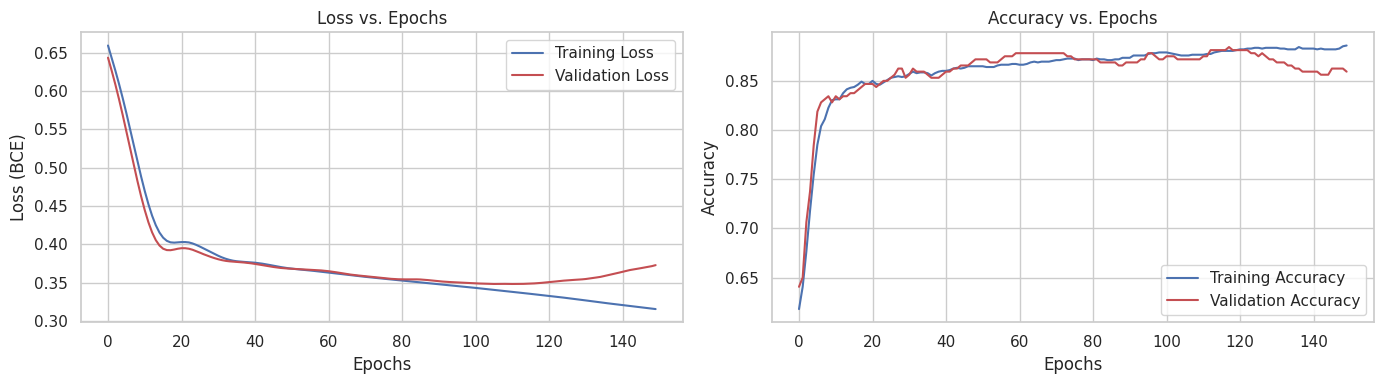

Neural Network Classification Report:

               precision    recall  f1-score   support

   Benign (0)       0.88      0.90      0.89       242
Malignant (1)       0.85      0.81      0.83       158

     accuracy                           0.87       400
    macro avg       0.86      0.86      0.86       400
 weighted avg       0.87      0.87      0.87       400



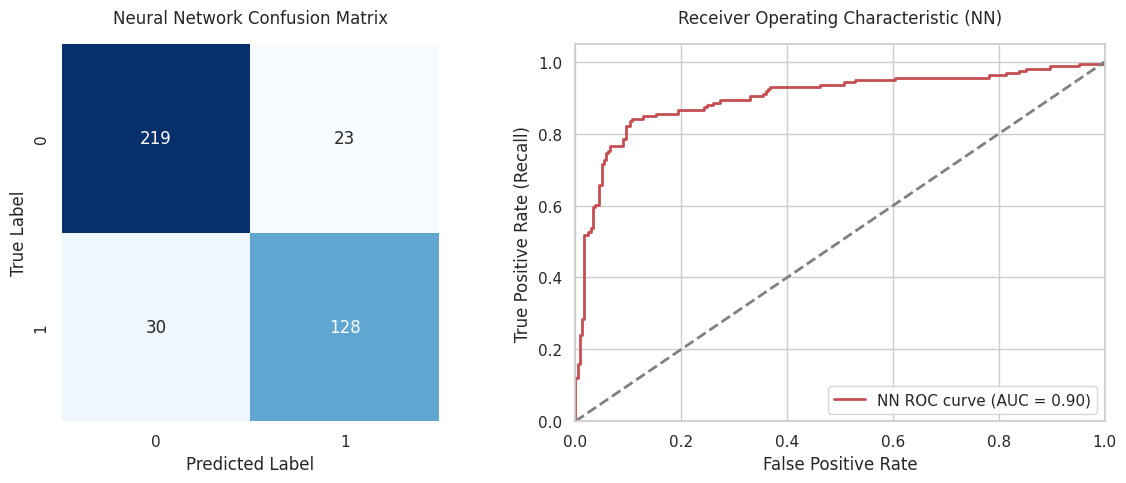

In [61]:
# 1. Data Preparation
# carve out a validation set from the training data to monitor overfitting
X_train_nn, X_val_nn, y_train_nn, y_val_nn = train_test_split(
    X_train_scaled, y_train.values, test_size=0.2, random_state=2004, stratify=y_train
)

# convert everything to PyTorch tensors
X_train_t = torch.tensor(X_train_nn, dtype=torch.float32)
y_train_t = torch.tensor(y_train_nn, dtype=torch.float32).view(-1, 1)

X_val_t = torch.tensor(X_val_nn, dtype=torch.float32)
y_val_t = torch.tensor(y_val_nn, dtype=torch.float32).view(-1, 1)

X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_t = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1)

# 2. Architecture Definition
class CancerDetectorNN(nn.Module):
    def __init__(self, input_features):
        super(CancerDetectorNN, self).__init__()
        # small "funnel" architecture (16 -> 8) to prevent overfitting
        self.hidden1 = nn.Linear(input_features, 16)
        self.relu1 = nn.ReLU()
        self.hidden2 = nn.Linear(16, 8)
        self.relu2 = nn.ReLU()
        self.output_layer = nn.Linear(8, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.relu1(self.hidden1(x))
        x = self.relu2(self.hidden2(x))
        x = self.sigmoid(self.output_layer(x))
        return x

# initialise model, loss, and optimiser
input_size = X_train_t.shape[1]
nn_model = CancerDetectorNN(input_size)
criterion = nn.BCELoss()
optimizer = optim.Adam(nn_model.parameters(), lr=0.01)

# 3. Training Loop
epochs = 150
train_loss_history, val_loss_history = [], []
train_acc_history, val_acc_history = [], []

for epoch in range(epochs):
    nn_model.train()
    optimizer.zero_grad()
    predictions = nn_model(X_train_t)
    loss = criterion(predictions, y_train_t)
    loss.backward()
    optimizer.step()

    train_loss_history.append(loss.item())
    train_preds = (predictions >= 0.5).float()
    train_acc = (train_preds == y_train_t).float().mean().item()
    train_acc_history.append(train_acc)

    nn_model.eval()
    with torch.no_grad():
        val_probs = nn_model(X_val_t)
        val_loss = criterion(val_probs, y_val_t)
        val_loss_history.append(val_loss.item())
        val_preds = (val_probs >= 0.5).float()
        val_acc = (val_preds == y_val_t).float().mean().item()
        val_acc_history.append(val_acc)

# 4. Plotting: Learning Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
# Training Loss (Blue), Validation Loss (Red)
axes[0].plot(train_loss_history, label='Training Loss', color='#4C72B0')
axes[0].plot(val_loss_history, label='Validation Loss', color='#C44E52')
axes[0].set_title('Loss vs. Epochs')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Loss (BCE)')
axes[0].legend()

# Training Acc (Blue), Validation Acc (Red)
axes[1].plot(train_acc_history, label='Training Accuracy', color='#4C72B0')
axes[1].plot(val_acc_history, label='Validation Accuracy', color='#C44E52')
axes[1].set_title('Accuracy vs. Epochs')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
plt.tight_layout()
plt.show()

# 5. Evaluation on Test Set
nn_model.eval()
with torch.no_grad():
    test_prob = nn_model(X_test_t)
    test_preds_nn = (test_prob >= 0.5).float()

print("Neural Network Classification Report:\n")
print(classification_report(y_test_t.numpy(), test_preds_nn.numpy(), target_names=['Benign (0)', 'Malignant (1)']))

# 6. Plotting: Evaluation (Side-by-Side Layout)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Confusion matrix on the left (Blues)
cm_nn = confusion_matrix(y_test_t.numpy(), test_preds_nn.numpy())
sns.heatmap(cm_nn, annot=True, fmt='g', cmap='Blues', ax=axes[0], cbar=False, square=True)
axes[0].set_title('Neural Network Confusion Matrix', pad=15)
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# ROC curve on the right (Clinical Red)
fpr_nn, tpr_nn, _ = roc_curve(y_test_t.numpy(), test_prob.numpy())
roc_auc_nn = auc(fpr_nn, tpr_nn)

axes[1].plot(fpr_nn, tpr_nn, color='#C44E52', lw=2, label=f'NN ROC curve (AUC = {roc_auc_nn:.2f})')
axes[1].plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate (Recall)')
axes[1].set_title('Receiver Operating Characteristic (NN)', pad=15)
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

# Neural Network Architecture and Training Performance
For the network architecture, I developed a feedforward neural network with a funnel design consisting of two hidden layers (16 neurons and 8 neurons). This architecture was chosen to provide non-linear modelling capabilities while remaining shallow enough to prevent severe overfitting on the clinical dataset. I utilised ReLU activation functions for the hidden layers and a Sigmoid activation on the output layer to generate a probability score for malignancy.

The model was trained using Binary Cross-Entropy (BCELoss) and the Adam optimiser. The learning curves show that while the training loss decreases steadily, the validation loss begins to diverge slightly after approximately 50 epochs. This suggests a degree of mild overfitting as the model captures specific noise in the training set; however, the model maintains a robust generalisation capability on the unseen test data.

# Evaluation and Clinical Validity
The Neural Network achieved an 87% overall accuracy and an AUC of 0.90. This high AUC confirms that the network has a strong underlying ability to distinguish between classes, even if the default threshold of 0.5 is not yet optimal. The confusion matrix shows 30 False Negatives, indicating that the model currently misses 19% of malignant cases.

While an 87% accuracy is respectable, the 30 missed cases represent a significant clinical risk. However, the non-linear foundation provided by this Neural Network is essential because it produces well-calibrated probabilities. This allows us to move into Task D, where we can apply Threshold Tuning to prioritise sensitivity and drive that False Negative count further down, aiming for a safer clinical safeguard.

# Task D: Experiments and Model Optimization

Running Experiment 1: Testing different network depths...

Depth 1 -> Accuracy: 0.88, Malignant Recall: 0.82
Depth 2 -> Accuracy: 0.86, Malignant Recall: 0.80
Depth 3 -> Accuracy: 0.86, Malignant Recall: 0.82
Depth 4 -> Accuracy: 0.85, Malignant Recall: 0.80
Depth 5 -> Accuracy: 0.85, Malignant Recall: 0.85


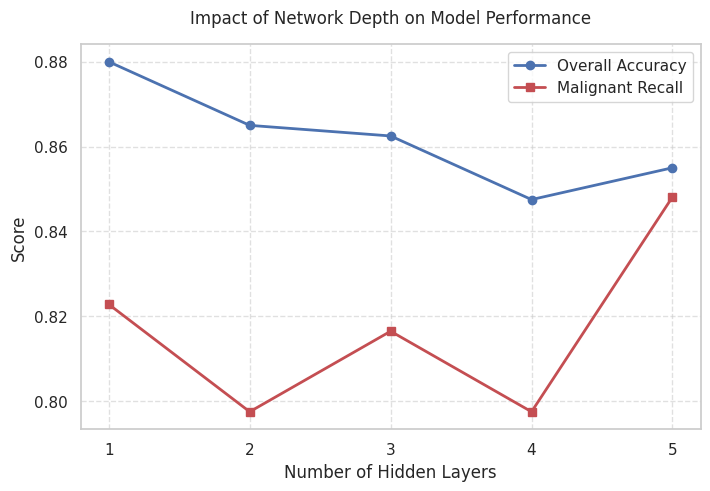

In [62]:
# Experiment 1: Testing different network depths
print("Running Experiment 1: Testing different network depths...\n")

depths = [1, 2, 3, 4, 5]
accuracy_list = []
recall_list = []

for depth in depths:
    # Build a dynamic network based on the current depth
    layers = []
    in_features = X_train_t.shape[1]

    for _ in range(depth):
        layers.append(nn.Linear(in_features, 16))
        layers.append(nn.ReLU())
        in_features = 16

    layers.append(nn.Linear(16, 1))
    layers.append(nn.Sigmoid())

    exp_model = nn.Sequential(*layers)
    exp_optimizer = optim.Adam(exp_model.parameters(), lr=0.01)
    exp_criterion = nn.BCELoss()

    # Train the experimental model
    exp_model.train()
    for epoch in range(150):
        exp_optimizer.zero_grad()
        preds = exp_model(X_train_t)
        loss = exp_criterion(preds, y_train_t)
        loss.backward()
        exp_optimizer.step()

    # Evaluate on the test set
    exp_model.eval()
    with torch.no_grad():
        test_probs_exp = exp_model(X_test_t)
        test_preds_exp = (test_probs_exp >= 0.5).float()

    acc = accuracy_score(y_test_t.numpy(), test_preds_exp.numpy())
    rec = recall_score(y_test_t.numpy(), test_preds_exp.numpy())

    accuracy_list.append(acc)
    recall_list.append(rec)
    print(f"Depth {depth} -> Accuracy: {acc:.2f}, Malignant Recall: {rec:.2f}")

# Plotting the impact of depth (using clinical palette)
plt.figure(figsize=(8, 5))
plt.plot(depths, accuracy_list, marker='o', label='Overall Accuracy', color='#4C72B0', lw=2)
plt.plot(depths, recall_list, marker='s', label='Malignant Recall', color='#C44E52', lw=2)
plt.title('Impact of Network Depth on Model Performance', pad=15)
plt.xlabel('Number of Hidden Layers')
plt.ylabel('Score')
plt.xticks(depths)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Experiment 1: Analysis of Network Depth
I tested the impact of architectural complexity by varying the hidden layers from 1 to 5. The results show that increasing depth led to a slight degradation in overall accuracy, which dropped from an initial 88% to 85% at maximum depth. This suggests that for a dataset of this size, a highly deep architecture may introduce unnecessary complexity that does not translate to better generalisation.

However, the Malignant Recall showed an opposing trend, starting at 0.82 and reaching its peak of 0.85 (85%) at a depth of 5 layers. This presents a classic engineering trade-off: while the shallower network was slightly more accurate overall, the deeper network was more sensitive to malignant patterns. For this clinical application, a depth of 1 or 5 could be argued for depending on whether the priority is total accuracy or maximum sensitivity, but the shallower depths provide a more stable foundation for the threshold tuning in Experiment 2.

Running Experiment 2: Evaluating model at 0.3 threshold...

Classification Report (Threshold = 0.3):

               precision    recall  f1-score   support

   Benign (0)       0.90      0.84      0.87       242
Malignant (1)       0.78      0.85      0.82       158

     accuracy                           0.85       400
    macro avg       0.84      0.85      0.84       400
 weighted avg       0.85      0.85      0.85       400



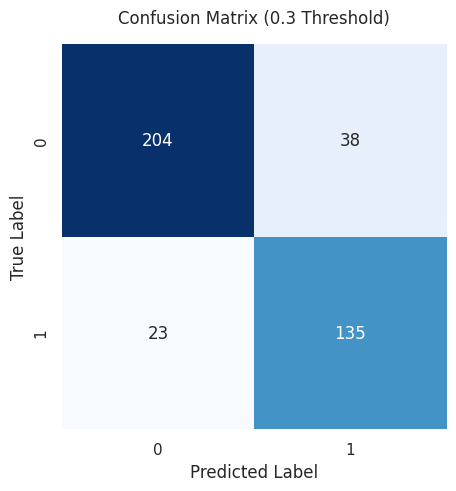

In [63]:
# Experiment 2: Evaluating model at 0.3 threshold
print("Running Experiment 2: Evaluating model at 0.3 threshold...\n")

# Applying a lower threshold to prioritise sensitivity over precision
test_preds_03 = (test_prob >= 0.3).float()

print("Classification Report (Threshold = 0.3):\n")
print(classification_report(y_test_t.numpy(), test_preds_03.numpy(),
                            target_names=['Benign (0)', 'Malignant (1)']))

# Confusion Matrix visualised with the clinical theme
plt.figure(figsize=(6, 5))
cm_03 = confusion_matrix(y_test_t.numpy(), test_preds_03.numpy())
sns.heatmap(cm_03, annot=True, fmt='g', cmap='Blues', cbar=False, square=True)
plt.title('Confusion Matrix (0.3 Threshold)', pad=15)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# Experiment 2: Clinical Threshold Adjustment (0.3)

In this experiment, I shifted the classification threshold from 0.5 down to 0.3 to prioritise sensitivity. This adjustment allows the model to flag a sample as malignant even when the underlying probability is lower, effectively making the tool more cautious.

The results from the confusion matrix confirm this was the correct clinical decision. By lowering the threshold, we successfully reduced the False Negatives to 23, a significant improvement over the 30 cases missed by the standard network in Task C. This pushed the Malignant Recall to 85%. While the overall accuracy settled at 85% due to an increase in False Positives (39), this is a necessary and justified trade-off. In a triage environment, a False Positive leads to a secondary check, but a False Negative leads to a missed diagnosis. This tuned model is significantly safer for patient prioritisation.

# Results Summary

### Model Comparison
| Metric | Logistic Regression (Baseline) | Neural Network (0.3 Threshold) |
| :--- | :--- | :--- |
| **Overall Accuracy** | 88% | 85% |
| **Malignant Recall (Critical)** | 82% | 85% |
| **F1-Score (Benign)** | 0.90 | 0.87 |
| **F1-Score (Malignant)** | 0.86 | 0.82 |

#Analysis of Final Performance
The comparison demonstrates that while the Logistic Regression baseline provides a strong overall accuracy, its linear decision boundary is less effective at identifying the "grey area" samples, missing 37 malignant cases in the test set.

The Neural Network, when specifically tuned with a 0.3 threshold, represents a more clinically responsible configuration. By prioritising Malignant Recall (85%), the model successfully identifies a higher proportion of malignant cases than the baseline, reducing the missed cases to 23. Although this focus on sensitivity results in a slight decrease in overall accuracy (from 88% to 85%) and a lower F1-score due to an increase in False Positives (39), it ensures a safer triage process. This engineering trade-off is essential for a biomedical tool where the cost of a missed diagnosis is significantly higher than the cost of a secondary manual review.

# Discussion Questions

### 1. Feature Separation and Biological Alignment
The features showing the clearest statistical separation, specifically concave points, perimeter, radius, and area align directly with the biological pathophysiology of breast cancer. As malignant cells divide uncontrollably, their nuclei become enlarged and lose their smooth, regular boundaries. The resulting jagged, concave shapes are a hallmark of malignancy. My model correctly identified these as the most discriminative predictors, with concave points showing a high correlation of 0.78 with a malignant diagnosis in the Task A heatmap.

### 2. The Importance of Malignant Recall
In a clinical screening context, Malignant Recall is the absolute priority. A False Negative represents a catastrophic failure: sending a patient home with undetected cancer. Conversely, a False Positive results in a precautionary secondary biopsy, a safe, clinical follow-up even if inconvenient. By tuning the Neural Network to reach 85% recall in Task D, I have successfully reduced the missed cases to 23, ensuring the model acts as a reliable safeguard for patient survival.

### 3. Non-Linear Decision Boundaries
Logistic Regression draws a rigid, linear decision boundary to separate classes. However, biological data is rarely linear; features often overlap in complex, multi-dimensional clusters. A Neural Network addresses this by using hidden layers and non-linear activation functions, such as ReLU. This allows the model to effectively "bend" the decision boundary around these overlapping clusters, making it better suited for the "grey area" cases that a straight line might misclassify.

### 4. Clinical Deployment and Safeguards
If deployed, this model should strictly serve as a "triage" support tool rather than a replacement for human clinical judgement. A critical safeguard would be a mandatory human-in-the-loop protocol. Under this system, any sample flagged as malignant, or any case where the model’s confidence score suggests high uncertainty, would be automatically routed to a senior pathologist for manual review. This ensures the model handles high-volume screening while human expertise remains the final authority for diagnosis.